# **Employee Salary Prediction**






In [ ]:
# ------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# ------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------

df = pd.read_csv("employee_salary.csv")

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!

First 5 rows:
        job_title experience_level employment_type work_models  work_year  \
0   Data Engineer        Mid-level       Full-time      Remote       2024   
1   Data Engineer        Mid-level       Full-time      Remote       2024   
2  Data Scientist     Senior-level       Full-time      Remote       2024   
3  Data Scientist     Senior-level       Full-time      Remote       2024   
4    BI Developer        Mid-level       Full-time     On-site       2024   

  employee_residence  salary salary_currency  salary_in_usd company_location  \
0      United States  148100             USD         148100    United States   
1      United States   98700             USD          98700    United States   
2      United States  140032             USD         140032    United States   
3      United States  100022             USD         100022    United States   
4      United States  120000             USD         120000    United States   

  company_si

# New Section

In [ ]:
# ------------------------------------------
# 3. UNDERSTANDING THE DATA
# ------------------------------------------

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
print(df.info())

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Column names:
Index(['job_title', 'experience_level', 'employment_type', 'work_models',
       'work_year', 'employee_residence', 'salary', 'salary_currency',
       'salary_in_usd', 'company_location', 'company_size'],
      dtype='object')

Data types:
job_title             object
experience_level      object
employment_type       object
work_models           object
work_year              int64
employee_residence    object
salary                 int64
salary_currency       object
salary_in_usd          int64
company_location      object
company_size          object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11087 entries, 0 to 11086
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   job_title           11087 non-null  object
 1   experience_level    11087 non-null  object
 2   employment_type     11087 non-null  object
 3   work_models         11087 non-null 

In [ ]:
# ------------------------------------------
# 4. DATA CLEANING
# ------------------------------------------

# Remove duplicate rows

df = df.drop_duplicates()

print("\nShape after removing duplicates:")
print(df.shape)


# Remove rows where target salary is missing

df = df.dropna(subset=["salary_in_usd"])

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Shape after removing duplicates:
(6599, 11)

Missing values after cleaning:
job_title             0
experience_level      0
employment_type       0
work_models           0
work_year             0
employee_residence    0
salary                0
salary_currency       0
salary_in_usd         0
company_location      0
company_size          0
dtype: int64


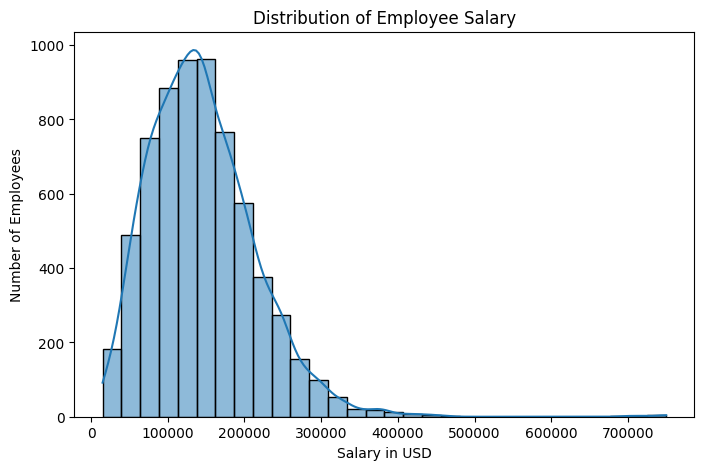

In [ ]:
# ------------------------------------------
# 5. DATA ANALYSIS / EDA
# ------------------------------------------

# Salary distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    df["salary_in_usd"],
    bins=30,
    kde=True
)

plt.title("Distribution of Employee Salary")
plt.xlabel("Salary in USD")
plt.ylabel("Number of Employees")

plt.show()

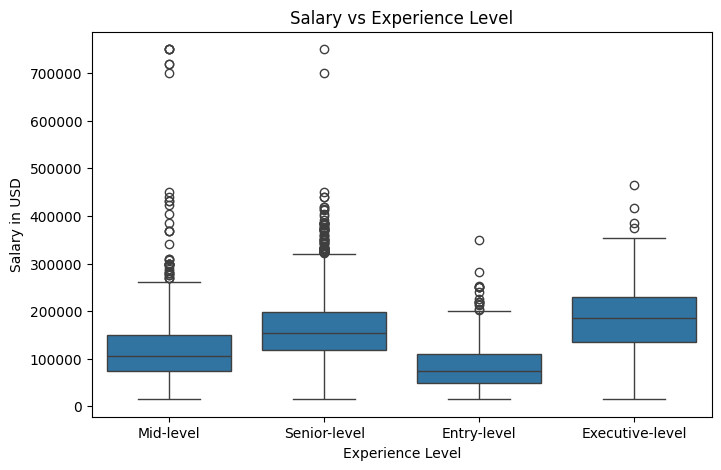

In [ ]:
# ------------------------------------------
# Salary by Experience Level
# ------------------------------------------

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="experience_level",
    y="salary_in_usd"
)

plt.title("Salary vs Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Salary in USD")

plt.show()

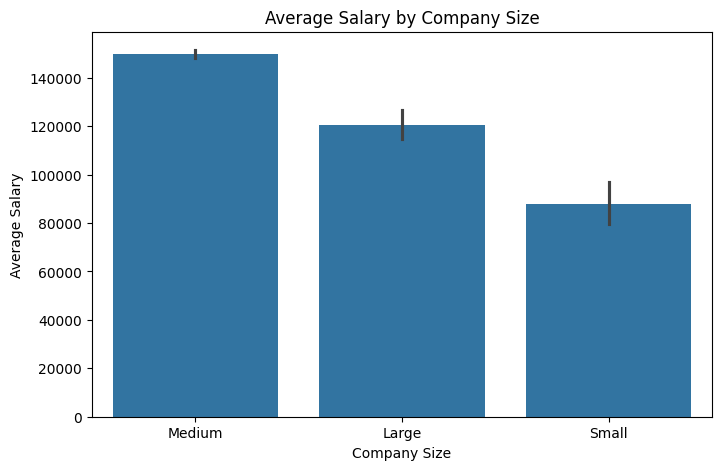

In [ ]:
# ------------------------------------------
# Average Salary by Company Size
# ------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="company_size",
    y="salary_in_usd"
)

plt.title("Average Salary by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Average Salary")

plt.show()


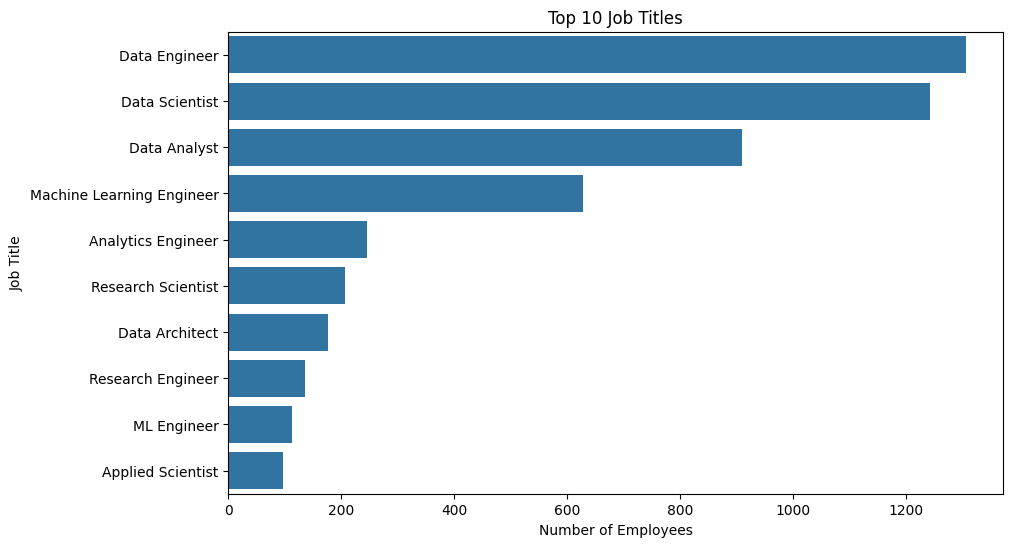

In [ ]:
# ------------------------------------------
# Top 10 Job Titles
# ------------------------------------------

top_jobs = df["job_title"].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title("Top 10 Job Titles")
plt.xlabel("Number of Employees")
plt.ylabel("Job Title")

plt.show()

In [ ]:
# ------------------------------------------
# Average Salary by Experience Level
# ------------------------------------------

average_salary = df.groupby(
    "experience_level"
)["salary_in_usd"].mean()

print("\nAverage salary by experience level:")
print(average_salary)



Average salary by experience level:
experience_level
Entry-level         84448.916814
Executive-level    189687.346457
Mid-level          119019.812537
Senior-level       162071.063581
Name: salary_in_usd, dtype: float64


In [ ]:
# ------------------------------------------
# Average Salary by Company Size
# ------------------------------------------

average_company_salary = df.groupby(
    "company_size"
)["salary_in_usd"].mean()

print("\nAverage salary by company size:")
print(average_company_salary)




Average salary by company size:
company_size
Large     120638.404218
Medium    149659.386689
Small      87687.458824
Name: salary_in_usd, dtype: float64


In [ ]:
print(df.columns)

Index(['job_title', 'experience_level', 'employment_type', 'work_models',
       'work_year', 'employee_residence', 'salary', 'salary_currency',
       'salary_in_usd', 'company_location', 'company_size'],
      dtype='object')



Correlation matrix:
               work_year    salary  salary_in_usd
work_year       1.000000 -0.095337       0.155993
salary         -0.095337  1.000000       0.043347
salary_in_usd   0.155993  0.043347       1.000000


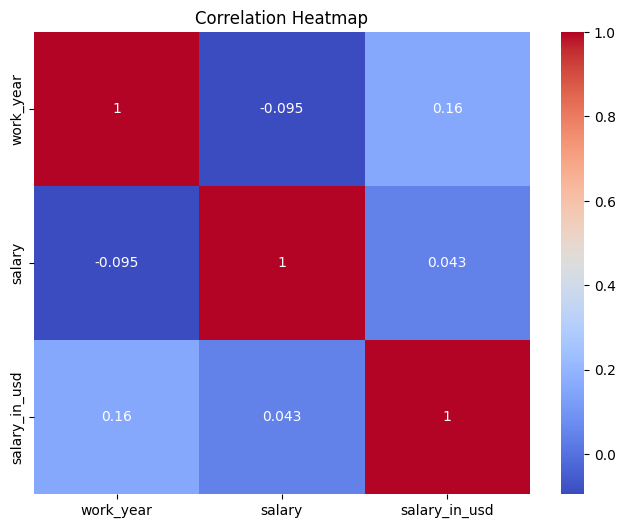

In [ ]:
# ------------------------------------------
# Correlation Analysis
# ------------------------------------------

numeric_data = df.select_dtypes(
    include=["int64", "float64"]
)

print("\nCorrelation matrix:")
print(numeric_data.corr())

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
# ------------------------------------------
# 6. FEATURE SELECTION
# ------------------------------------------

features = [
    "job_title",
    "experience_level",
    "employment_type",
    "work_models",
    "work_year",
    "employee_residence",
    "company_location",
    "company_size"
]

target = "salary_in_usd"


X = df[features]

y = df[target]


print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nFeature shape:")
print(X.shape)

print("\nTarget shape:")
print(y.shape)


Features:
        job_title experience_level employment_type work_models  work_year  \
0   Data Engineer        Mid-level       Full-time      Remote       2024   
1   Data Engineer        Mid-level       Full-time      Remote       2024   
2  Data Scientist     Senior-level       Full-time      Remote       2024   
3  Data Scientist     Senior-level       Full-time      Remote       2024   
4    BI Developer        Mid-level       Full-time     On-site       2024   

  employee_residence company_location company_size  
0      United States    United States       Medium  
1      United States    United States       Medium  
2      United States    United States       Medium  
3      United States    United States       Medium  
4      United States    United States       Medium  

Target:
0    148100
1     98700
2    140032
3    100022
4    120000
Name: salary_in_usd, dtype: int64

Feature shape:
(6599, 8)

Target shape:
(6599,)


In [ ]:
# ------------------------------------------
# 7. IDENTIFY NUMERICAL AND CATEGORICAL
# ------------------------------------------

numerical_features = [
    "work_year"
]

categorical_features = [
    "job_title",
    "experience_level",
    "employment_type",
    "work_models",
    "employee_residence",
    "company_location",
    "company_size"
]


In [ ]:
# ------------------------------------------
# 8. DATA PREPROCESSING
# ------------------------------------------

preprocessor = ColumnTransformer(

    transformers=[

        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )

    ],

    remainder="passthrough"
)

In [ ]:
# ------------------------------------------
# 9. TRAIN TEST SPLIT
# ------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining data shape:")
print(X_train.shape)

print("\nTesting data shape:")
print(X_test.shape)



Training data shape:
(5279, 8)

Testing data shape:
(1320, 8)


In [ ]:
# ------------------------------------------
# 10. CREATE RANDOM FOREST MODEL
# ------------------------------------------

model = RandomForestRegressor(

    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


In [ ]:
# ------------------------------------------
# 11. CREATE PIPELINE
# ------------------------------------------

pipeline = Pipeline(

    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "model",
            model
        )

    ]

)


In [ ]:
# ------------------------------------------
# 12. TRAIN MODEL
# ------------------------------------------

print("\nTraining model...")

pipeline.fit(
    X_train,
    y_train
)

print("Model training completed!")



Training model...
Model training completed!


In [ ]:
# ------------------------------------------
# 13. MAKE PREDICTIONS
# ------------------------------------------

y_pred = pipeline.predict(X_test)


In [ ]:
# ------------------------------------------
# 14. MODEL EVALUATION
# ------------------------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)


print("\n========== MODEL EVALUATION ==========")

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)



========== MODEL EVALUATION ==========
Mean Absolute Error: 44663.630178144485
Mean Squared Error: 4042250222.748701
Root Mean Squared Error: 63578.693150682964
R2 Score: 0.31219164354221307


In [ ]:
# ------------------------------------------
# 15. ACTUAL VS PREDICTED SALARY
# ------------------------------------------

comparison = pd.DataFrame({

    "Actual Salary": y_test.values,

    "Predicted Salary": y_pred

})

print("\nActual vs Predicted:")
print(comparison.head(10))



Actual vs Predicted:
   Actual Salary  Predicted Salary
0         230000     195756.077063
1         104000     161229.388613
2         100000     188427.454872
3          63040      60981.798095
4         238000     176729.128726
5          36773      55086.456190
6          57223      73651.922667
7         104000     138433.369634
8         150000     125059.455556
9          77300      56209.222222


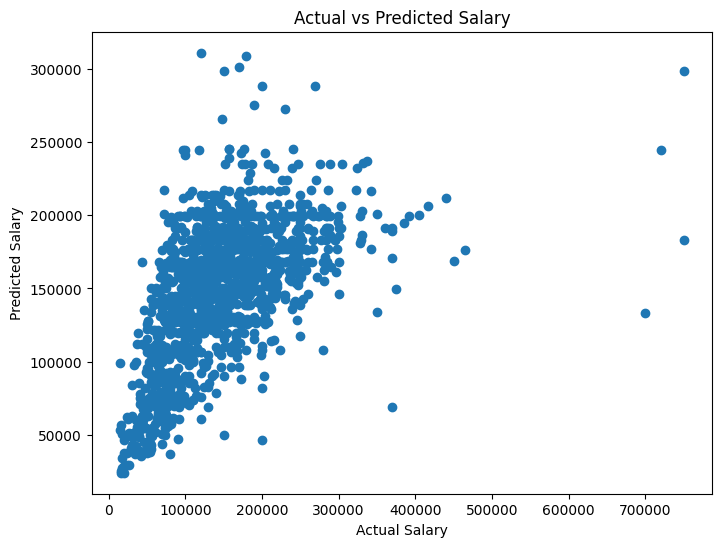

In [ ]:
# ------------------------------------------
# 16. ACTUAL VS PREDICTED GRAPH
# ------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Salary")

plt.ylabel("Predicted Salary")

plt.title("Actual vs Predicted Salary")

plt.show()


In [ ]:
# ------------------------------------------
# 17. SAVE MODEL
# ------------------------------------------

joblib.dump(
    pipeline,
    "employee_salary_model.pkl"
)

print("\nModel saved successfully!")

print("File: employee_salary_model.pkl")



Model saved successfully!
File: employee_salary_model.pkl


In [ ]:
# ------------------------------------------
# 18. TEST NEW EMPLOYEE
# ------------------------------------------

new_employee = pd.DataFrame({

    "job_title": ["Data Scientist"],

    "experience_level": ["SE"],

    "employment_type": ["FT"],

    "work_models": ["Remote"],

    "work_year": [2024],

    "employee_residence": ["US"],

    "company_location": ["US"],

    "company_size": ["M"]

})


predicted_salary = pipeline.predict(
    new_employee
)


print("\n========== NEW EMPLOYEE PREDICTION ==========")

print(
    "Predicted Salary:",
    round(predicted_salary[0], 2),
    "USD"
)


========== NEW EMPLOYEE PREDICTION ==========
Predicted Salary: 58388.17 USD


In [ ]:
print(df["work_models"].value_counts())

work_models
On-site    3813
Remote     2561
Hybrid      225
Name: count, dtype: int64
